# 01 · The SDE front end

`api.sde.SDE` turns a model written as stochastic equations into the MSRJD action and the mean-field equations. This tutorial covers every ingredient of the builder:

| Method | Declares |
|---|---|
| `.parameter(name, default, domain=, indexed_by=)` | a parameter (scalar, or indexed by populations) |
| `.population(name, size=)` | an index set: a field declared on it is a vector |
| `.field(name, population=)` | a dynamical field; its response field is `<name>t` |
| `.drift(field, f)` | $\dot x = f$ |
| `.equation(field, lhs, rhs)` | a general linear operator on the left, e.g. `'(tau*Dt + 1)*v'` |
| `.noise(name, source, couples=)` | a noise source from `api.noise` (tutorial 02) |
| `.point_process(name, rate)` | a spike train with conditional intensity `rate` (tutorial 03) |
| `.define_function(name, args, expr)` | a named function, usable in drifts and rates |
| `.define_kernel(name, ...)` | a causal convolution kernel, used as `Conv(name, x)` |
| `.interpretation('ito' \| 'stratonovich')` | the stochastic calculus (Itô is the default) |
| `.show()`, `.equations()`, `.notes` | what was derived |
| `.build()`, `.to_builder()` | the model dict / the equivalent hand-written builder (tutorial 06) |

Run time: under two minutes.

In [1]:
%matplotlib inline
try:
    preparser(False)   # Sage kernel: plain Python syntax and numbers in the cells below
except NameError:
    pass
import os, sys, time, warnings
import numpy as np
import matplotlib.pyplot as plt
# locate the repository root (the folder holding the 'api' package) from any working directory
_root = os.path.abspath('')
while _root != os.path.dirname(_root) and not os.path.isdir(os.path.join(_root, 'api')):
    _root = os.path.dirname(_root)
sys.path.insert(0, _root)
os.chdir(_root)
def ells(r):   # C(tau) per loop order (real parts), a list indexed by the loop order
    return [np.real(np.asarray(r['C_tau_by_ell'][l])) for l in sorted(r['C_tau_by_ell'])]
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

In [2]:
from api.sde import SDE
from api.noise import Gaussian
from api.delay import Kernel
from api import compute_cumulants

## 1. Populations and indexed parameters

A population is an index set. A field declared on population `P` is a vector $x_i$, $i \in P$; a parameter with `indexed_by=['P']` is a vector and one with `indexed_by=['P', 'P']` a matrix. Inside expressions, bare names are indexed by `i` automatically, and sums over a population are written as Python generator expressions.

Two coupled nonlinear units with independent noise:

$$\dot x_i = -\mu_i x_i - \varepsilon x_i^3 + \sum_j J_{ij} x_j + \xi_i .$$

In [3]:
pair = (SDE('coupled pair')
        .population('P', size=2)
        .parameter('mu', default=[1.0, 1.5], indexed_by=['P'], domain='positive')
        .parameter('J', default=[[0.0, 0.4], [0.3, 0.0]], indexed_by=['P', 'P'])
        .parameter('eps', default=0.05, domain='positive')
        .parameter('D', default=0.5, domain='positive')
        .field('x', population='P')
        .equation('x', lhs='(Dt + mu)*x', rhs='-eps*x^3 + sum(J[i,j]*x[j] for j in P)')
        .noise('xi', Gaussian(var='2*D'), couples={'x': 1}, population='P'))
pair.show();

# SDE 'coupled pair' (ito)
.set_action_text('''
sum(
    xt[i]*((Dt + mu[i])*x[i] - (-eps*x[i]^3 + sum(J[i,j]*x[j] for j in P)))
    - (D*xt[i]^2)
    for i in P)
''')
.equation(lhs='(Dt + mu[i])*x[i]', rhs='-eps*x[i]^3 + sum(J[i,j]*x[j] for j in P)', population='P')


A population sum cannot be split into "linear" and "nonlinear" parts automatically, so the restoring term is written on the left-hand side: `.equation(field, lhs, rhs)` states $\mathcal L x = \text{rhs}$ with any linear operator $\mathcal L$ (here $\partial_t + \mu_i$); `.drift(x, f)` is the shorthand for `lhs='Dt*x'`.

External legs carry 1-based population indices: `('x', 1)` and `('x', 2)` are the two units. The cross-correlation $C_{12}(\tau) = \kappa(x_1(t), x_2(t+\tau))$ is not symmetric in $\tau$ because the coupling is not.

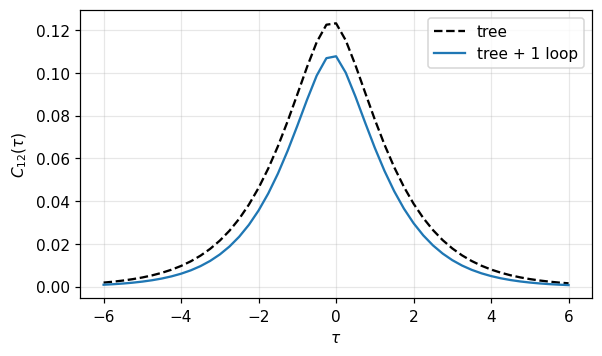

In [4]:
tau = np.linspace(-6, 6, 49)
r = compute_cumulants(pair.build(), k=2, max_ell=1, external_fields=[('x', 1), ('x', 2)],
                      tau_grid=tau, parallel=False, verbose=False)
c = ells(r)
plt.figure(figsize=(6, 3.4))
plt.plot(tau, c[0], 'k--', label='tree'); plt.plot(tau, c[0] + c[1], label='tree + 1 loop')
plt.xlabel(r'$\tau$'); plt.ylabel(r'$C_{12}(\tau)$'); plt.legend(); plt.show()

## 2. General left-hand sides, functions and kernels

`.equation(field, lhs, rhs)` allows any linear differential operator on the left (it must contain the time derivative `Dt`). A *function* is declared once and called by name. A *kernel* is a causal filter $g(t)$; `Conv(g, x)` is $(g * x)(t) = \int_0^\infty g(s)\,x(t-s)\,\mathrm ds$. Kernels can be given by a time expression, a frequency image, or composed from `api.delay.Kernel`: `Kernel.exponential(tau)` $= e^{-t/\tau}/\tau$, `Kernel.alpha(tau)` $= t\,e^{-t/\tau}/\tau^2$, `Kernel.delay(d)` $= \delta(t-d)$, and products of them (a product is the convolution of the kernels).

A rate unit with a sigmoidal gain driven through a slow alpha-shaped filter:

$$\tau\,\dot v = -v + w\,(g * f(v)) + \xi,\qquad f(v) = \frac{1}{1+e^{-\beta v}} - \tfrac12 .$$

A convolution acts on a *field*, so the filtered output $u = f(v)$ is made a field with its own (fast) equation; here it is written with a short relaxation time $\tau_u$.

In [5]:
unit = (SDE('rate unit')
        .parameter('tau', default=1.0, domain='positive')
        .parameter('tau_u', default=0.05, domain='positive')
        .parameter('w', default=-1.0)
        .parameter('beta', default=2.0, domain='positive')
        .parameter('taus', default=0.5, domain='positive')
        .parameter('D', default=0.05, domain='positive')
        .define_function('f', ['v'], '1/(1 + exp(-beta*v)) - 1/2')
        .define_kernel('g', kernel=Kernel.alpha('taus'))
        .field('v').field('u')
        .equation('v', lhs='(tau*Dt + 1)*v', rhs='w*Conv(g, u)')
        .equation('u', lhs='(tau_u*Dt + 1)*u', rhs='f(v)')
        .noise('xi', Gaussian(var='2*D'), couples={'v': 1}))
unit.show()
print('\nmean-field equations:')
for e in unit.equations():
    print('  ', e['lhs'], '=', e['rhs'])

# SDE 'rate unit' (ito)
.set_action_text('''
sum(
    vt[i]*((tau*Dt + 1)*v[i] - (w*Conv(g, u[i])))
    + ut[i]*((tau_u*Dt + 1)*u[i] - (f[i](v[i])))
    - (D*vt[i]^2)
    for i in pop)
''')
.equation(lhs='(tau*Dt + 1)*v[i]', rhs='w*((1))*(u[i])', population='pop')
.equation(lhs='(tau_u*Dt + 1)*u[i]', rhs='f[i](v[i])', population='pop')

mean-field equations:
   (tau*Dt + 1)*v[i] = w*((1))*(u[i])
   (tau_u*Dt + 1)*u[i] = f[i](v[i])


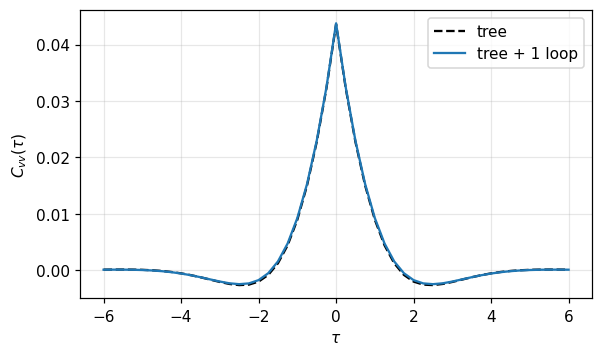

mean-field values: {'vstar': [0.0], 'ustar': [0.0]}


In [6]:
r = compute_cumulants(unit.build(), k=2, max_ell=1, external_fields=[('v', 1), ('v', 1)],
                      tau_grid=tau, parallel=False, verbose=False)
c = ells(r)
plt.figure(figsize=(6, 3.4))
plt.plot(tau, c[0], 'k--', label='tree'); plt.plot(tau, c[0] + c[1], label='tree + 1 loop')
plt.xlabel(r'$\tau$'); plt.ylabel(r'$C_{vv}(\tau)$'); plt.legend(); plt.show()
print('mean-field values:', {k: [float(x) for x in np.atleast_1d(v)] for k, v in r['mf_values'].items()})

The negative feedback through the slow alpha filter shapes the autocorrelation; the saddle is $v^* = 0$, where $f$ is odd, so the one-loop term comes from its cubic part.

## 3. Itô and Stratonovich

With multiplicative noise the calculus matters. The coupling coefficient may depend on the fields; `.interpretation('stratonovich')` converts to the Itô form the action needs and adds the noise-induced drift. Compare the two derived actions (only the drift changes):

In [7]:
def mult(mode):
    return (SDE(f'multiplicative ({mode})')
            .parameter('mu', default=1.0, domain='positive').parameter('s', default=0.3)
            .field('x').drift('x', '-mu*x')
            .noise('xi', Gaussian(var='1'), couples={'x': 's*(1 + x^2)'})
            .interpretation(mode))
for mode in ('ito', 'stratonovich'):
    mult(mode).show(); print()

# SDE 'multiplicative (ito)' (ito)
.set_action_text('''
sum(
    xt[i]*(Dt*x[i] - (-mu*x[i]))
    - ((1/2)*(x[i]^2 + 1)^2*s^2*xt[i]^2)
    for i in pop)
''')
.equation(lhs='Dt*x[i] + mu*x[i]', rhs='0', population='pop')
# note: mean-field equation of 'x': linear term -mu*x[i] moved to the lhs.

# SDE 'multiplicative (stratonovich)' (stratonovich)
.set_action_text('''
sum(
    xt[i]*(Dt*x[i] - (-mu*x[i] + (s^2*x[i]^3 + s^2*x[i])))
    - ((1/2)*(x[i]^2 + 1)^2*s^2*xt[i]^2)
    for i in pop)
''')
.equation(lhs='-s^2*x[i] + Dt*x[i] + mu*x[i]', rhs='s^2*x[i]^3', population='pop')
# note: Stratonovich -> Ito: drift of 'x' += s^2*x[i]^3 + s^2*x[i] (source 'xi').
# note: mean-field equation of 'x': linear term (s^2 - mu)*x[i] moved to the lhs.



## 4. What the builder produced

* `.build()` returns the model dict that `compute_cumulants` takes.
* `.to_builder()` returns the equivalent `TemporalModelBuilder`; `show()` prints it as code you can copy into a hand-written model (tutorial 06).
* `.notes` records any rewriting the builder did (for example completing a left-hand side so that the mean-field equation defines $x^*$).
* Names that clash with built-ins (`e`, `pi`, `I`, `t`, `theta`, `Dt`, ...) are refused with a message.

In [8]:
print(unit.notes)
try:
    SDE('bad').parameter('e', default=1.0)
except Exception as err:
    print(type(err).__name__, ':', err)

[]
SDEError : parameter name 'e' is reserved (built-in constant, keyword or function); choose another name (e.g. e0).
